# Energy Consumption Prediction Using Machine Learning

**Goal:** Predict household appliance energy consumption (`Appliances`, Wh) every 10 minutes using indoor temperature/humidity, outdoor weather, lighting use, and time information.

**Dataset:** Appliances Energy Prediction — UCI Machine Learning Repository  
https://archive.ics.uci.edu/dataset/374/appliances%2Benergy%2Bprediction

This notebook follows the required project flow:

1. Read & Explore  
2. EDA — prove problems before fixing  
3. Data Cleaning with justification  
4. Feature Engineering  
5. Train/Test split before learned preprocessing  
6. Train & compare regression models  
7. Final report + 5-line summary


## 0) Imports and reproducibility
We import only the libraries needed for analysis, visualization, preprocessing, modeling, and evaluation. A fixed random state is used so results are reproducible.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)


# 1) Read and Explore
We first inspect the dataset exactly as received. We check shape, column names, data types, missing values, duplicate rows, descriptive statistics, and the target distribution. No cleaning is applied yet.

In [2]:
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'data' / 'energydata_complete.csv'

# Colab-friendly fallback: if the CSV is not present, upload it manually.
if not DATA_PATH.exists():
    try:
        from google.colab import files
        print('Upload energydata_complete.csv')
        uploaded = files.upload()
        if 'energydata_complete.csv' not in uploaded:
            raise FileNotFoundError('Please upload energydata_complete.csv')
        DATA_PATH = Path('energydata_complete.csv')
    except ImportError:
        raise FileNotFoundError(f'Dataset not found at {DATA_PATH}')

df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (19735, 29)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [3]:
print('Columns:')
print(df.columns.tolist())
print()
print('Data types:')
print(df.dtypes)


Columns:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Data types:
date               str
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object


In [4]:
print('Missing values by column:')
print(df.isna().sum())
print()
print('Total missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))


Missing values by column:
date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

Total missing values: 0
Duplicate rows: 0


In [5]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,19735,19735,2016-01-11 17:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Appliances,19735.0,NaN,NaN,NaN,97.694958,102.524891,10.0,50.0,60.0,100.0,1080.0
lights,19735.0,NaN,NaN,NaN,3.801875,7.935988,0.0,0.0,0.0,0.0,70.0
T1,19735.0,NaN,NaN,NaN,21.686571,1.606066,16.79,20.76,21.6,22.6,26.26
RH_1,19735.0,NaN,NaN,NaN,40.259739,3.979299,27.023333,37.333333,39.656667,43.066667,63.36
T2,19735.0,NaN,NaN,NaN,20.341219,2.192974,16.1,18.79,20.0,21.5,29.856667
RH_2,19735.0,NaN,NaN,NaN,40.42042,4.069813,20.463333,37.9,40.5,43.26,56.026667
T3,19735.0,NaN,NaN,NaN,22.267611,2.006111,17.2,20.79,22.1,23.29,29.236
RH_3,19735.0,NaN,NaN,NaN,39.2425,3.254576,28.766667,36.9,38.53,41.76,50.163333
T4,19735.0,NaN,NaN,NaN,20.855335,2.042884,15.1,19.53,20.666667,22.1,26.2


### Initial observations
- `date` is read as text (`object`), so it needs conversion to datetime before extracting time features.
- The target is `Appliances` in Wh.
- We explicitly verify missing values and duplicates rather than assuming they exist.
- `rv1` and `rv2` are documented by UCI as random variables included to test filtering of non-predictive attributes; we will prove their weak relationship before dropping them.


# 2) EDA — Prove Problems Before Fixing
The project requires evidence of data issues before cleaning. We visualize the target distribution, outliers/skewness, random variables, lighting behavior, and correlations.

Appliances skewness: 3.386
count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64


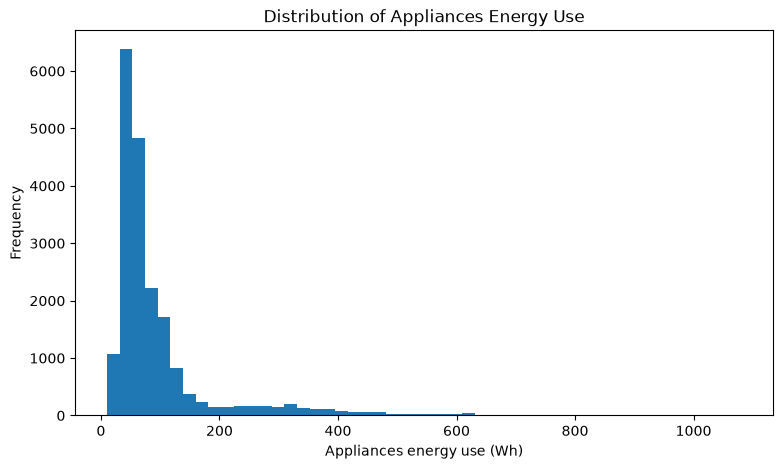

In [6]:
target_skew = df['Appliances'].skew()
print(f'Appliances skewness: {target_skew:.3f}')
print(df['Appliances'].describe())

plt.figure(figsize=(9, 5))
plt.hist(df['Appliances'], bins=50)
plt.xlabel('Appliances energy use (Wh)')
plt.ylabel('Frequency')
plt.title('Distribution of Appliances Energy Use')
plt.show()


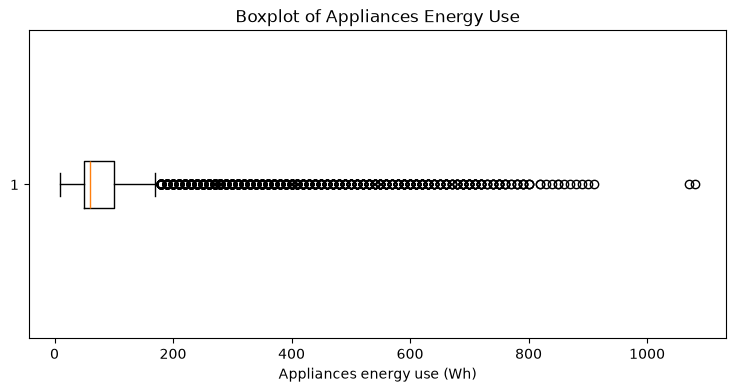

In [7]:
plt.figure(figsize=(9, 4))
plt.boxplot(df['Appliances'], orientation='horizontal')
plt.xlabel('Appliances energy use (Wh)')
plt.title('Boxplot of Appliances Energy Use')
plt.show()


**Interpretation:** The target is strongly right-skewed. Large energy-use values are not automatically removed because they can represent real appliance-use spikes. We will later test whether a log transformation helps a linear model.

Correlation with target:
rv1          -0.011145
rv2          -0.011145
Appliances    1.000000
Name: Appliances, dtype: float64


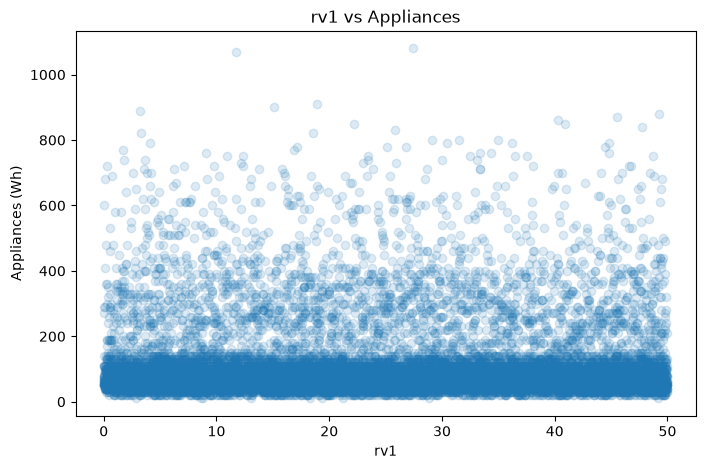

In [8]:
rv_corr = df[['rv1', 'rv2', 'Appliances']].corr()['Appliances']
print('Correlation with target:')
print(rv_corr)

plt.figure(figsize=(8, 5))
plt.scatter(df['rv1'], df['Appliances'], alpha=0.15)
plt.xlabel('rv1')
plt.ylabel('Appliances (Wh)')
plt.title('rv1 vs Appliances')
plt.show()


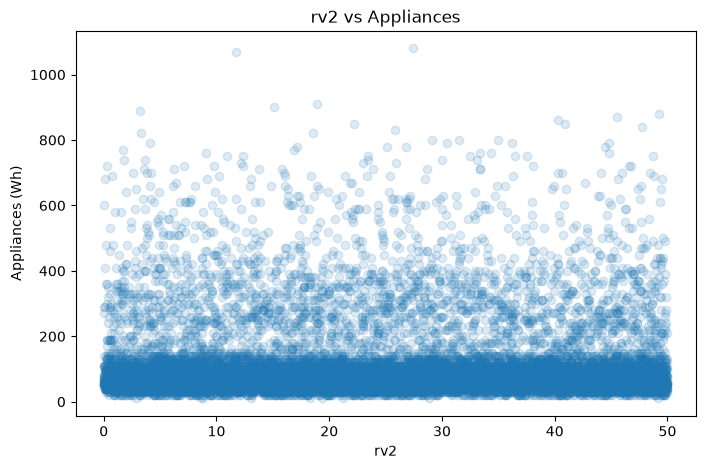

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['rv2'], df['Appliances'], alpha=0.15)
plt.xlabel('rv2')
plt.ylabel('Appliances (Wh)')
plt.title('rv2 vs Appliances')
plt.show()


**Interpretation:** `rv1` and `rv2` show essentially no predictive relationship with the target and are documented as random variables. They will be removed for a justified reason, not arbitrarily.

Percentage of zero values in lights: 77.28%


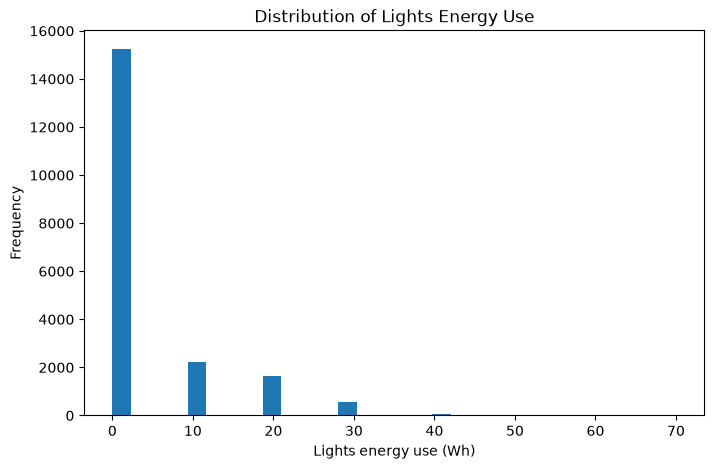

In [10]:
lights_zero_pct = (df['lights'] == 0).mean() * 100
print(f'Percentage of zero values in lights: {lights_zero_pct:.2f}%')

plt.figure(figsize=(8, 5))
plt.hist(df['lights'], bins=30)
plt.xlabel('Lights energy use (Wh)')
plt.ylabel('Frequency')
plt.title('Distribution of Lights Energy Use')
plt.show()


**Interpretation:** `lights` contains many zeros, but zero means the lights were off, so this is meaningful information and should be kept rather than treated as missing data.

In [11]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

target_corr = corr['Appliances'].drop('Appliances').sort_values(key=np.abs, ascending=False)
print('Top absolute correlations with Appliances:')
print(target_corr.head(12))


Top absolute correlations with Appliances:
lights       0.197278
RH_out      -0.152282
T2           0.120073
T6           0.117638
T_out        0.099155
RH_8        -0.094039
Windspeed    0.087122
RH_1         0.086031
T3           0.085060
RH_6        -0.083178
RH_2        -0.060465
RH_7        -0.055642
Name: Appliances, dtype: float64


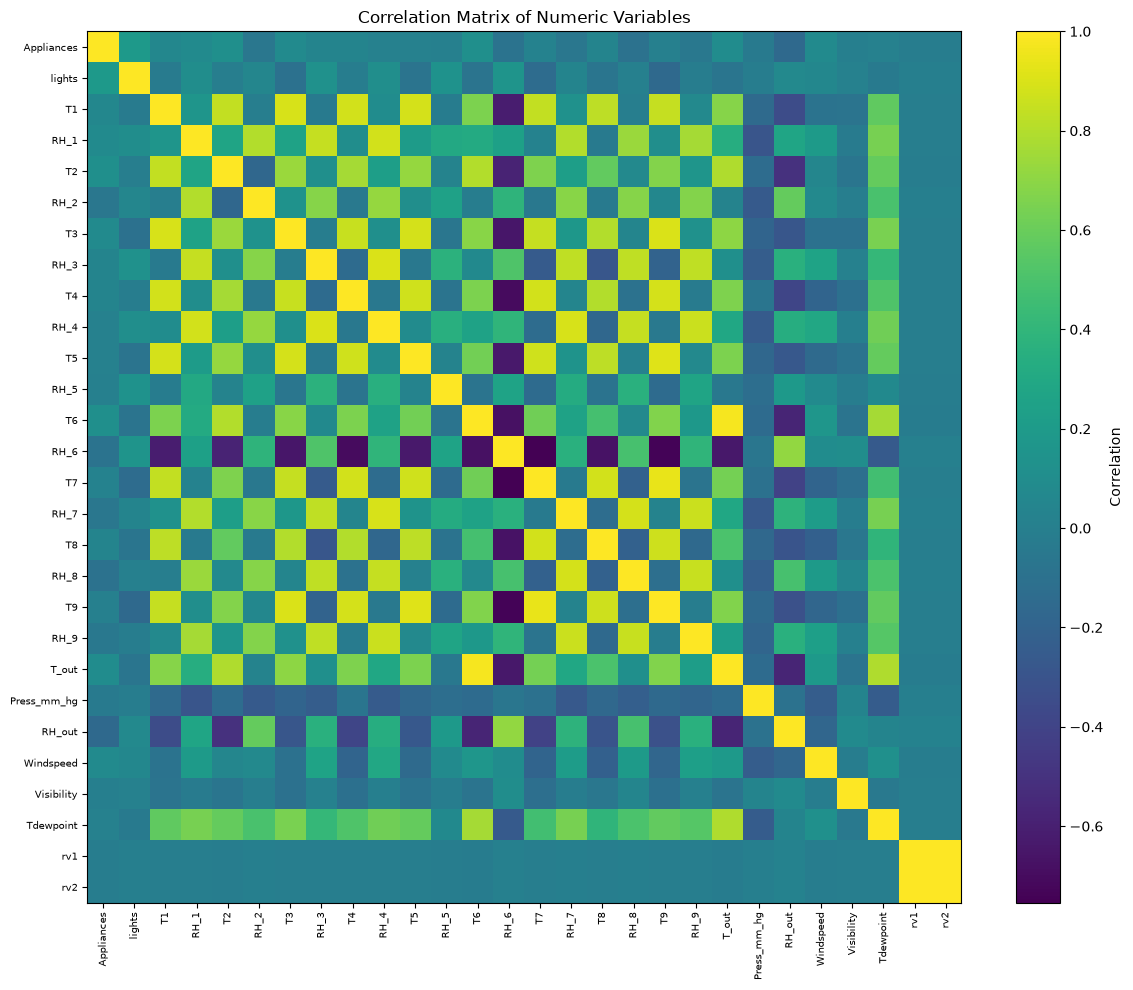

In [12]:
plt.figure(figsize=(12, 10))
plt.imshow(corr, aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=7)
plt.title('Correlation Matrix of Numeric Variables')
plt.tight_layout()
plt.show()


### EDA findings before cleaning
1. No missing values were found.
2. No duplicate rows were found.
3. `date` needs conversion from text to datetime.
4. `Appliances` is strongly right-skewed.
5. `rv1` and `rv2` are random/non-predictive variables and should be removed.
6. `lights` is zero-heavy but valid, so it is kept.
7. Numeric features have very different scales, so scaling will be applied to the linear model **after the train/test split**.


# 3) Data Cleaning
We now apply only the cleaning decisions supported by the previous evidence. We do not invent missing-value treatment or delete valid target spikes.

In [13]:
clean_df = df.copy()

# Convert date to a true datetime type.
clean_df['date'] = pd.to_datetime(clean_df['date'], errors='raise')

# Drop documented random variables.
clean_df = clean_df.drop(columns=['rv1', 'rv2'])

# No missing-value imputation and no duplicate removal are needed because checks found none.
print('Shape after cleaning:', clean_df.shape)
print('Remaining missing values:', int(clean_df.isna().sum().sum()))
print('Remaining duplicates:', int(clean_df.duplicated().sum()))
clean_df.head()


Shape after cleaning: (19735, 27)
Remaining missing values: 0
Remaining duplicates: 0


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9


# 4) Feature Engineering
We create deterministic features from existing row values. These transformations do not learn parameters from the dataset, so they can be created before the split.

**Time features.** `hour` and `dayofweek` are cyclical, so they are encoded with sine/cosine to avoid artificial jumps between 23:00 and 00:00 or between Sunday and Monday. Once `hour_sin`/`hour_cos` and `dow_sin`/`dow_cos` exist, the raw `hour` and `dayofweek` carry the *same information* in a less suitable form, so they are used only as temporary helpers and are **not** kept as model inputs. `month` is kept as a coarse seasonal signal.

**Feature review (duplicates / low value removed).**
- `hour`, `dayofweek` — exact duplicates of the sin/cos pairs → removed.
- `is_weekend` — fully derivable from `dayofweek` (already captured by `dow_sin`/`dow_cos`), near-zero importance in both Random Forest and Gradient Boosting → removed.
- `indoor_temp_mean`, `indoor_humidity_mean` — exact linear combinations of `T1..T9` / `RH_1..RH_9` (perfect multicollinearity for the linear model, no new information for trees) → removed.
- `temp_gap_indoor_out` — built from `indoor_temp_mean` and `T_out` (so it is also a linear combination of existing columns); dropping it gave equal or better scores on every model in our tests → removed.

All decisions were checked on the same train/test split (`random_state=42`) by comparing R² before and after each removal.

In [14]:
model_df = clean_df.copy()

# Temporary helpers (NOT kept as model inputs)
_hour = model_df['date'].dt.hour
_dow = model_df['date'].dt.day_of_week

# Seasonal signal
model_df['month'] = model_df['date'].dt.month

# Cyclical encodings (replace raw hour / dayofweek)
model_df['hour_sin'] = np.sin(2 * np.pi * _hour / 24)
model_df['hour_cos'] = np.cos(2 * np.pi * _hour / 24)
model_df['dow_sin'] = np.sin(2 * np.pi * _dow / 7)
model_df['dow_cos'] = np.cos(2 * np.pi * _dow / 7)

# The raw datetime column is now represented by numeric time features.
model_df = model_df.drop(columns=['date'])

print('Modeling shape:', model_df.shape)
model_df.head()

Modeling shape: (19735, 31)


,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,month,hour_sin,hour_cos,dow_sin,dow_cos
0,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,1,-0.965926,-0.258819,0.0,1.0
1,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,1,-0.965926,-0.258819,0.0,1.0
2,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,1,-0.965926,-0.258819,0.0,1.0
3,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,1,-0.965926,-0.258819,0.0,1.0
4,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,1,-0.965926,-0.258819,0.0,1.0


### Redundancy check on the final feature set
We confirm that no two remaining features are exact duplicates and list any pair with |correlation| > 0.95. `T6` and `T_out` are strongly correlated (both measure outdoor-side temperature), but removing either did not improve any model, so both are kept.

In [15]:
feat_df = model_df.drop(columns=['Appliances'])

# exact duplicate columns?
dup_cols = feat_df.T.duplicated().sum()
print('Exact duplicate feature columns:', int(dup_cols))

# highly correlated pairs
fc = feat_df.corr().abs()
pairs = [(a, b, round(fc.loc[a, b], 3))
         for i, a in enumerate(fc.columns) for b in fc.columns[i + 1:]
         if fc.loc[a, b] > 0.95]
print('Pairs with |corr| > 0.95:', pairs if pairs else 'none')
print('Final number of features:', feat_df.shape[1])
print(feat_df.columns.tolist())

Exact duplicate feature columns: 0
Pairs with |corr| > 0.95: [('T6', 'T_out', np.float64(0.975))]
Final number of features: 30
['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'month', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']


# 5) Train/Test Split — Before Learned Preprocessing
The target is `Appliances`. We use an 80/20 split with a fixed random state. Learned preprocessing is fitted only on the training set. In particular, `StandardScaler` is placed inside the linear-model pipeline so it never learns from test data.

**Important limitation:** UCI labels this dataset as time-series. A random split is used here to match the standard regression workflow taught in class, but a future production version should also evaluate a chronological holdout to test generalization to future periods.

In [16]:
X = model_df.drop(columns=['Appliances'])
y = model_df['Appliances']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (15788, 30)
X_test : (3947, 30)
y_train: (15788,)
y_test : (3947,)


## Target skewness experiment
Because the target is strongly right-skewed, we test a log-transformed linear regression as an additional experiment. Predictions are transformed back to Wh before evaluation, so all reported metrics stay in the original business unit.

# 6) Modeling and Evaluation
We compare five regression models:

- **Linear Regression** — required linear baseline, with train-only scaling through a pipeline.
- **Log-Linear Regression** — additional skewness experiment.
- **Random Forest Regressor** — non-linear bagging ensemble.
- **Extra Trees Regressor** — like Random Forest but with randomized split thresholds, which reduces variance and works well on noisy tabular data like this.
- **Gradient Boosting Regressor** — non-linear boosting ensemble (trees are built sequentially, each one correcting the errors of the previous ones).

Metrics:
- **R²:** higher is better.
- **MAE:** average absolute error in Wh; lower is better.
- **RMSE:** penalizes larger errors more strongly; lower is better.


In [17]:
def regression_metrics(y_true, y_pred):
    return {
        'R2': r2_score(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5
    }

results = {}
predictions = {}

linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
results['Linear Regression'] = regression_metrics(y_test, linear_pred)
predictions['Linear Regression'] = linear_pred

log_linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])
log_linear_model.fit(X_train, np.log1p(y_train))
log_linear_pred = np.expm1(log_linear_model.predict(X_test))
results['Log-Linear Regression'] = regression_metrics(y_test, log_linear_pred)
predictions['Log-Linear Regression'] = log_linear_pred

random_forest = RandomForestRegressor(
    n_estimators=150,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    max_features=0.8,
    min_samples_leaf=1
)
random_forest.fit(X_train, y_train)
rf_pred = random_forest.predict(X_test)
results['Random Forest'] = regression_metrics(y_test, rf_pred)
predictions['Random Forest'] = rf_pred

gradient_boosting = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    max_features=0.8,
    min_samples_leaf=3,
    random_state=RANDOM_STATE
)
gradient_boosting.fit(X_train, y_train)
gb_pred = gradient_boosting.predict(X_test)
results['Gradient Boosting'] = regression_metrics(y_test, gb_pred)
predictions['Gradient Boosting'] = gb_pred

extra_trees = ExtraTreesRegressor(
    n_estimators=300,
    max_features=0.7,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
extra_trees.fit(X_train, y_train)
et_pred = extra_trees.predict(X_test)
results['Extra Trees'] = regression_metrics(y_test, et_pred)
predictions['Extra Trees'] = et_pred

results_df = pd.DataFrame(results).T.sort_values('RMSE')
results_df


,R2,MAE,RMSE
Extra Trees,0.645719,26.669141,59.542606
Random Forest,0.606113,29.426130,62.782680
Gradient Boosting,0.514168,35.270534,69.726353
Linear Regression,0.201225,51.603372,89.405874
Log-Linear Regression,0.159136,43.012145,91.731116


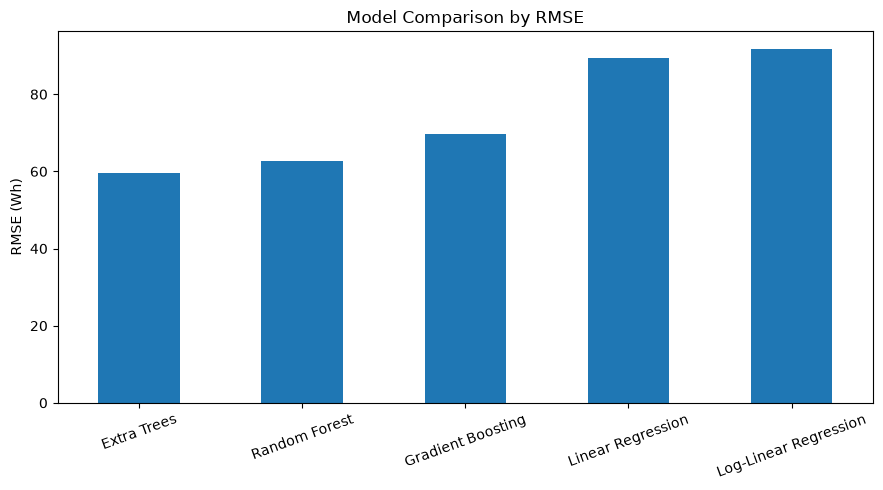

In [18]:
plt.figure(figsize=(9, 5))
results_df['RMSE'].sort_values().plot(kind='bar')
plt.ylabel('RMSE (Wh)')
plt.title('Model Comparison by RMSE')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


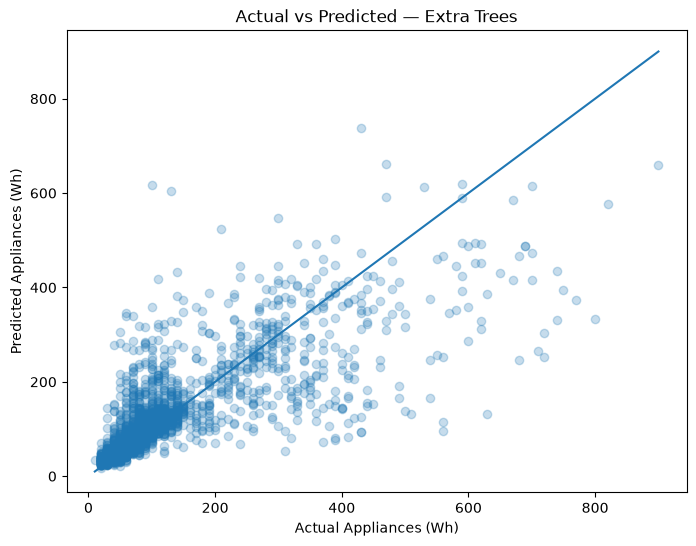

In [19]:
best_model_name = results_df.index[0]
best_pred = predictions[best_model_name]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_pred, alpha=0.25)
low = min(y_test.min(), best_pred.min())
high = max(y_test.max(), best_pred.max())
plt.plot([low, high], [low, high])
plt.xlabel('Actual Appliances (Wh)')
plt.ylabel('Predicted Appliances (Wh)')
plt.title(f'Actual vs Predicted — {best_model_name}')
plt.show()


## Feature importance
For the Random Forest model, feature importance provides an interpretable ranking of which variables contributed most to predictions. Importance is useful for interpretation, but it should not be read as proof of causation.

Top 10 features:
hour_sin       0.084838
hour_cos       0.075577
T3             0.051723
Press_mm_hg    0.045511
RH_3           0.044387
RH_2           0.036944
T8             0.036317
RH_5           0.036073
Tdewpoint      0.035855
RH_1           0.034963
dtype: float64


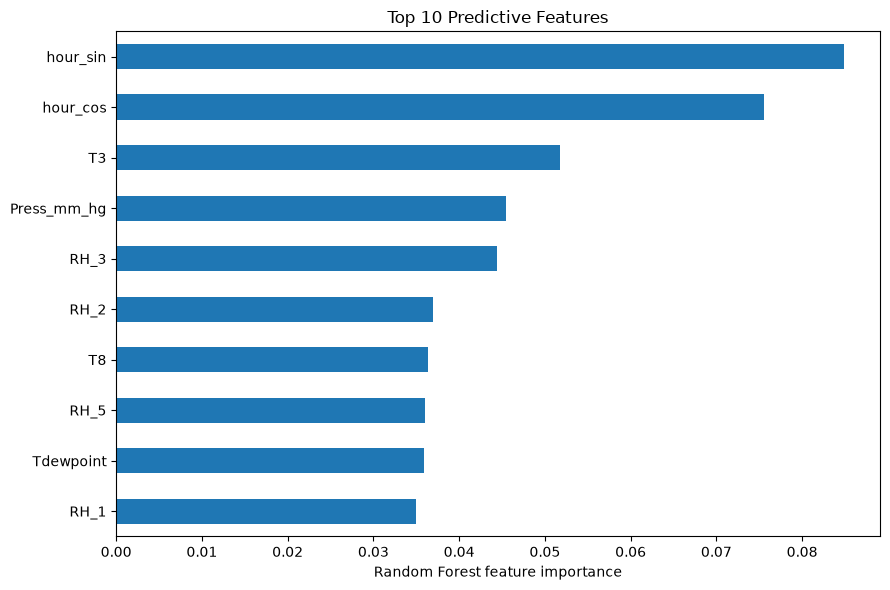

In [20]:
feature_importance = pd.Series(
    random_forest.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print('Top 10 features:')
print(feature_importance.head(10))

plt.figure(figsize=(9, 6))
feature_importance.head(10).sort_values().plot(kind='barh')
plt.xlabel('Random Forest feature importance')
plt.title('Top 10 Predictive Features')
plt.tight_layout()
plt.show()


# 7) Final Report and Recommendations
This report summarizes the random-split model comparison and the separately recorded chronological holdout. The chronological metrics are loaded from `reports/chronological_metrics.json`; they are not recomputed by this notebook cell. The two evaluations answer different questions and must not be compared as if they used the same test period.


In [21]:
from pathlib import Path
import json

best_model_name = results_df.index[0]
best_scores = results_df.loc[best_model_name]
top3_rf_features = feature_importance.head(3).index.tolist()

# A separate earlier-to-later holdout, evaluated by the project training script.
chronological_report = None
for metrics_path in [Path('../reports/chronological_metrics.json'), Path('reports/chronological_metrics.json')]:
    if metrics_path.is_file():
        chronological_report = json.loads(metrics_path.read_text(encoding='utf-8'))
        break

print('FINAL REPORT')
print('-' * 60)
print(f'Best model on random 80/20 split: {best_model_name}')
print(f'Random-split R²: {best_scores["R2"]:.3f}')
print(f'Random-split MAE: {best_scores["MAE"]:.2f} Wh')
print(f'Random-split RMSE: {best_scores["RMSE"]:.2f} Wh')
print(f'Top 3 RANDOM FOREST importance features (not Extra Trees): {", ".join(top3_rf_features)}')
if chronological_report:
    print(f'Chronological holdout ({chronological_report["model"]}): R²={chronological_report["r2"]:.3f}, MAE={chronological_report["mae"]:.2f} Wh, RMSE={chronological_report["rmse"]:.2f} Wh')
else:
    print('Chronological holdout: see reports/chronological_metrics.json (not found at this notebook working directory).')
print('\nInterpretation:')
print('- Time and environmental measurements provide predictive signals in this single-household dataset.')
print('- Random-split scores are not a measure of reliable future-period forecasting performance.')
print('\nLimitations:')
print('- Only one household and approximately 4.5 months of observations.')
print('- A chronological holdout shows much weaker generalization to a later period.')
print('- Feature importance is model-specific and does not prove causation.')
print('\nRecommendations:')
print('1. Improve and re-evaluate later-period forecasting with chronological validation or rolling-origin splits.')
print('2. Tune Extra Trees and compare other models under the SAME time-based validation protocol; do not select on the final test period.')
print('3. Reassess time features and check seasonality, drift, and leakage using controlled ablation experiments.')
print('4. Collect data across more households and seasons before claiming broader generalization.')
print('5. Document uncertainty and limit app use to demonstration until prospective performance is adequate.')


FINAL REPORT
------------------------------------------------------------
Best model on random 80/20 split: Extra Trees
Random-split R²: 0.646
Random-split MAE: 26.67 Wh
Random-split RMSE: 59.54 Wh
Top 3 RANDOM FOREST importance features (not Extra Trees): hour_sin, hour_cos, T3
Chronological holdout (Extra Trees): R²=-0.931, MAE=97.53 Wh, RMSE=126.50 Wh

Interpretation:
- Time and environmental measurements provide predictive signals in this single-household dataset.
- Random-split scores are not a measure of reliable future-period forecasting performance.

Limitations:
- Only one household and approximately 4.5 months of observations.
- A chronological holdout shows much weaker generalization to a later period.
- Feature importance is model-specific and does not prove causation.

Recommendations:
1. Improve and re-evaluate later-period forecasting with chronological validation or rolling-origin splits.
2. Tune Extra Trees and compare other models under the SAME time-based validation 

## Required 5-line Summary
This summary distinguishes the random-split results from the separate chronological evaluation and updates the next steps accordingly.


In [22]:
print(f'1. Best model on random split: {best_model_name}; R²={best_scores["R2"]:.3f}, MAE={best_scores["MAE"]:.2f} Wh, RMSE={best_scores["RMSE"]:.2f} Wh.')
if chronological_report:
    print(f'2. Chronological Extra Trees holdout: R²={chronological_report["r2"]:.3f}, MAE={chronological_report["mae"]:.2f} Wh, RMSE={chronological_report["rmse"]:.2f} Wh; future-period performance is weak.')
else:
    print('2. Chronological holdout was run separately; refer to reports/chronological_metrics.json.')
print(f'3. Top 3 Random Forest importance features: {", ".join(top3_rf_features)} (not Extra Trees importance).')
print(f'4. Main data limitation: one household, short coverage, right-skewed target (skewness={target_skew:.3f}); removed rv1 and rv2.')
print('5. Next: improve time-based validation and model tuning, audit temporal features, and test on additional homes and seasons.')


1. Best model on random split: Extra Trees; R²=0.646, MAE=26.67 Wh, RMSE=59.54 Wh.
2. Chronological Extra Trees holdout: R²=-0.931, MAE=97.53 Wh, RMSE=126.50 Wh; future-period performance is weak.
3. Top 3 Random Forest importance features: hour_sin, hour_cos, T3 (not Extra Trees importance).
4. Main data limitation: one household, short coverage, right-skewed target (skewness=3.386); removed rv1 and rv2.
5. Next: improve time-based validation and model tuning, audit temporal features, and test on additional homes and seasons.


## Final project checklist
- [x] Explored shape, types, missing values, duplicates, and all columns
- [x] Proved issues with plots before cleaning
- [x] Explained every cleaning decision
- [x] Added useful engineered features
- [x] Split Train/Test before learned preprocessing
- [x] Fit the scaler only on training data through a pipeline
- [x] Compared a linear model with four other regression models (log-linear, Random Forest, Extra Trees, Gradient Boosting)
- [x] Reviewed time features and removed duplicated / low-value ones after adding sin/cos encodings
- [x] Evaluated using R², MAE, and RMSE
- [x] Investigated target skewness and a log transformation
- [x] Reported feature importance, limitations, and recommendations
- [x] Added the required 5-line summary
